In [1]:
import re
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

I0000 00:00:1794720446.802359   17144 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794720446.804349   17144 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794720447.082889   17144 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794720448.920265   17144 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

In [3]:
file_path = "document3.txt"

with open(file_path, "r", encoding="utf-8") as file:
    text = file.read()

print("Original Text:\n")
print(text)

Original Text:

The speed of transmission is an important point of difference between the two viruses. Influenza has a shorter median incubation period (the time from infection to appearance of symptoms) and a shorter serial interval (the time between successive cases) than COVID-19 virus. The serial interval for COVID-19 virus is estimated to be 5-6 days, while for influenza virus, the serial interval is 3 days. This means that influenza can spread faster than COVID-19. 

Further, transmission in the first 3-5 days of illness, or potentially pre-symptomatic transmission –transmission of the virus before the appearance of symptoms – is a major driver of transmission for influenza. In contrast, while we are learning that there are people who can shed COVID-19 virus 24-48 hours prior to symptom onset, at present, this does not appear to be a major driver of transmission. 

The reproductive number – the number of secondary infections generated from one infected individual – is understood 

In [4]:
text = text.lower()

text = re.sub(r'[^a-z\s]', '', text)

sentences = text.split('.')

sentences = [sentence.strip() for sentence in sentences if sentence.strip()]

print("Preprocessed Sentences:\n")

for sentence in sentences:
    print(sentence)

Preprocessed Sentences:

the speed of transmission is an important point of difference between the two viruses influenza has a shorter median incubation period the time from infection to appearance of symptoms and a shorter serial interval the time between successive cases than covid virus the serial interval for covid virus is estimated to be  days while for influenza virus the serial interval is  days this means that influenza can spread faster than covid 

further transmission in the first  days of illness or potentially presymptomatic transmission transmission of the virus before the appearance of symptoms  is a major driver of transmission for influenza in contrast while we are learning that there are people who can shed covid virus  hours prior to symptom onset at present this does not appear to be a major driver of transmission 

the reproductive number  the number of secondary infections generated from one infected individual  is understood to be between  and  for covid virus h

In [5]:
tokenizer = Tokenizer()

tokenizer.fit_on_texts(sentences)

word_index = tokenizer.word_index

vocab_size = len(word_index) + 1

print("Vocabulary Size:", vocab_size)

print("\nVocabulary:")

print(word_index)

Vocabulary Size: 93

Vocabulary:
{'the': 1, 'of': 2, 'transmission': 3, 'influenza': 4, 'covid': 5, 'virus': 6, 'for': 7, 'is': 8, 'to': 9, 'a': 10, 'and': 11, 'between': 12, 'serial': 13, 'interval': 14, 'than': 15, 'be': 16, 'days': 17, 'are': 18, 'viruses': 19, 'shorter': 20, 'time': 21, 'from': 22, 'appearance': 23, 'symptoms': 24, 'while': 25, 'this': 26, 'that': 27, 'can': 28, 'in': 29, 'major': 30, 'driver': 31, 'number': 32, 'speed': 33, 'an': 34, 'important': 35, 'point': 36, 'difference': 37, 'two': 38, 'has': 39, 'median': 40, 'incubation': 41, 'period': 42, 'infection': 43, 'successive': 44, 'cases': 45, 'estimated': 46, 'means': 47, 'spread': 48, 'faster': 49, 'further': 50, 'first': 51, 'illness': 52, 'or': 53, 'potentially': 54, 'presymptomatic': 55, 'before': 56, 'contrast': 57, 'we': 58, 'learning': 59, 'there': 60, 'people': 61, 'who': 62, 'shed': 63, 'hours': 64, 'prior': 65, 'symptom': 66, 'onset': 67, 'at': 68, 'present': 69, 'does': 70, 'not': 71, 'appear': 72, 'r

In [6]:
window_size = 2

contexts = []
targets = []

for sentence in sentences:

    words = sentence.split()

    for i in range(window_size, len(words) - window_size):

        context = (
            words[i-2:i] +
            words[i+1:i+3]
        )

        target = words[i]

        contexts.append([
            word_index[word] for word in context
        ])

        targets.append(word_index[target])


X = np.array(contexts)

y = np.array(targets)

print("Context Data Shape:", X.shape)

print("Target Data Shape:", y.shape)

print("\nFirst 5 Training Pairs:")

for i in range(min(5, len(X))):

    context_words = [
        list(word_index.keys())[list(word_index.values()).index(idx)]
        for idx in X[i]
    ]

    target_word = list(word_index.keys())[list(word_index.values()).index(y[i])]

    print("Context:", context_words, "Target:", target_word)

Context Data Shape: (173, 4)
Target Data Shape: (173,)

First 5 Training Pairs:
Context: ['the', 'speed', 'transmission', 'is'] Target: of
Context: ['speed', 'of', 'is', 'an'] Target: transmission
Context: ['of', 'transmission', 'an', 'important'] Target: is
Context: ['transmission', 'is', 'important', 'point'] Target: an
Context: ['is', 'an', 'point', 'of'] Target: important


In [7]:
embedding_dim = 50

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        input_length=4
    ),

    GlobalAveragePooling1D(),

    Dense(64, activation='relu'),

    Dense(vocab_size, activation='softmax')
])

model.summary()

/home/najanrohit0/.local/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

E0000 00:00:1794720534.744352   17144 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [9]:
history = model.fit(
    X,
    y,
    epochs=100,
    batch_size=16,
    verbose=1
)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0231 - loss: 4.5317      
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.0925 - loss: 4.5162 
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1214 - loss: 4.5006 
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1445 - loss: 4.4802 
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1387 - loss: 4.4533 
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1445 - loss: 4.4162 
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1329 - loss: 4.3657 
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.1387 - loss: 4.3009 
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1329 - loss: 4.2102 
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1272 - loss: 4.1052 
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1098 - loss: 3.9882     
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9884 - loss: 0.3864 
Epoch 69/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9884 - loss: 0.3660 
Epoch 70/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9884 - loss: 0.3495 
Epoch 71/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9884 - loss: 0.3337 
Epoch 72/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9769 - loss: 0.3185 
Epoch 73/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9884 - loss: 0.3023 
Epoch 74/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9884 - loss: 0.2919 
Epoch 75/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9884 - loss: 0.2782 
Epoch 76/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9884 - loss: 0.2663 
Epoch 77/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9884 - loss: 0.2571 
Epoch 78/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9884 - loss: 0.2460 
Epoch 79/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - ac

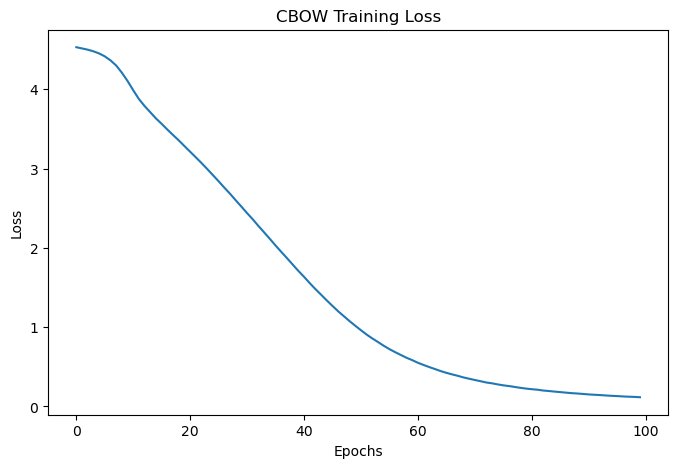

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'])

plt.title("CBOW Training Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.show()

In [11]:
def predict_word(context_words):

    context_indices = [
        word_index[word.lower()] for word in context_words
    ]

    context_input = np.array([context_indices])

    prediction = model.predict(context_input, verbose=0)

    predicted_index = np.argmax(prediction)

    for word, index in word_index.items():

        if index == predicted_index:
            return word


# Example context
context = ["influenza", "has", "incubation", "period"]

predicted_word = predict_word(context)

print("Context Words:", context)

print("Predicted Target Word:", predicted_word)

Context Words: ['influenza', 'has', 'incubation', 'period']
Predicted Target Word: for
